In [1]:
%pip install -q pandas tensorflow numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


# Deep Learning for Function Estimation
### Amir, 2025, NUS SoC ACE

#### We'll try to estimate the quality of red wine samples based on their physical and chemical features
#### We compute and report the mean absolute error, MAE

In [2]:
# CNN version
# Regression Example With wine dataset ...
import pandas as pd
from pandas import read_csv
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense , Dropout
from tensorflow.keras.layers import Conv1D
from tensorflow.keras.layers import MaxPooling1D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt


In [3]:
# mounting the Google drive
# from google.colab import drive

# drive.mount('/content/drive')

# # Load the dataset
# fp = "/content/drive/My Drive/emeritus/2025/Module2-3/wine_r2_t_noheader.csv"
fp = "wine_r2_t_noheader.csv"

In [4]:

# load dataset to a Pandas dataframe
dataframe = read_csv(fp , header=None)
# copy only values to a numpy n dimensional array, ndarray
dataset = dataframe.values

# split into input (X) and output (Y) variables
X = dataset[:,0:11]
Y = dataset[:,11]

print(X.shape)
X = X.reshape(X.shape[0], X.shape[1], 1)
print(X.shape)


(1599, 11)
(1599, 11, 1)


In [5]:
print(type(dataset))
print(dataset.shape)
print(dataframe.describe())
print( dataframe.head() )

<class 'numpy.ndarray'>
(1599, 12)
                0            1            2            3            4   \
count  1599.000000  1599.000000  1599.000000  1599.000000  1599.000000   
mean      8.319637     0.527821     0.270976     2.538806     0.087467   
std       1.741096     0.179060     0.194801     1.409928     0.047065   
min       4.600000     0.120000     0.000000     0.900000     0.012000   
25%       7.100000     0.390000     0.090000     1.900000     0.070000   
50%       7.900000     0.520000     0.260000     2.200000     0.079000   
75%       9.200000     0.640000     0.420000     2.600000     0.090000   
max      15.900000     1.580000     1.000000    15.500000     0.611000   

                5            6            7            8            9   \
count  1599.000000  1599.000000  1599.000000  1599.000000  1599.000000   
mean     15.874922    46.467792     0.996747     3.311113     0.658149   
std      10.460157    32.895324     0.001887     0.154386     0.169507   
mi

In [6]:
# define base model, a deep covolutional one
# structure comprisses 2 1d convolution layers with 16 and 12 filters, filters are 3x1
# then maxpooling for downsampling, a fully connected dense layer with 12 neurons
# Droput layer with 20% at the end
#
def baseline_model():
    # create model
    model = Sequential()
    model.add(Conv1D(16, 3, activation="relu", input_shape=(11,1)))
    model.add(Conv1D(12, 3, activation="relu"))
    model.add(MaxPooling1D())
    model.add(Flatten())
    model.add(Dense(12, input_dim=8, kernel_initializer='normal', activation='relu'))
    model.add( Dropout(0.2) )
    model.add(Dense(1, kernel_initializer='normal'))
    # Compile model
    model.compile(loss='mean_squared_error', optimizer='adam')
    return model


In [7]:
# splitting the train and test subsets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

In [8]:
# training the model for 900 epochs and testing the trained model with the training data
# we report the training error
estimator = baseline_model()
estimator.fit(X_train, Y_train, epochs=1400, verbose=2)
prediction = estimator.predict(X_train)

train_error =  np.abs(Y_train - prediction)
mean_error = np.mean(train_error)
min_error = np.min(train_error)
max_error = np.max(train_error)
std_error = np.std(train_error)
# print('\nTraining results:\nmean=',mean_error,'\nmin=',min_error,'\nmax=',max_error,'\nstd=',std_error)

print('\nTraining results:')
print('MAE =', mean_error)
print('Min error =', min_error)
print('Max error =', max_error)
print('STD error =', std_error)

Epoch 1/1400


/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


40/40 - 0s - 8ms/step - loss: 17.5361
Epoch 2/1400
40/40 - 0s - 795us/step - loss: 10.4203
Epoch 3/1400
40/40 - 0s - 675us/step - loss: 9.2325
Epoch 4/1400
40/40 - 0s - 638us/step - loss: 7.0478
Epoch 5/1400
40/40 - 0s - 617us/step - loss: 4.7200
Epoch 6/1400
40/40 - 0s - 636us/step - loss: 3.0969
Epoch 7/1400
40/40 - 0s - 629us/step - loss: 2.7644
Epoch 8/1400
40/40 - 0s - 629us/step - loss: 2.3229
Epoch 9/1400
40/40 - 0s - 614us/step - loss: 2.3260
Epoch 10/1400
40/40 - 0s - 636us/step - loss: 2.5022
Epoch 11/1400
40/40 - 0s - 619us/step - loss: 2.3967
Epoch 12/1400
40/40 - 0s - 614us/step - loss: 2.1819
Epoch 13/1400
40/40 - 0s - 607us/step - loss: 2.2475
Epoch 14/1400
40/40 - 0s - 623us/step - loss: 2.2959
Epoch 15/1400
40/40 - 0s - 628us/step - loss: 2.3467
Epoch 16/1400
40/40 - 0s - 651us/step - loss: 2.1490
Epoch 17/1400
40/40 - 0s - 686us/step - loss: 2.2436
Epoch 18/1400
40/40 - 0s - 652us/step - loss: 2.1058
Epoch 19/1400
40/40 - 0s - 624us/step - loss: 2.1547
Epoch 20/1400
4

In [9]:
# showing the real and predicted quality scores for the training data
df = pd.DataFrame({'Actual': Y_train, 'Predicted': prediction.ravel() })
df1 = df.tail(25)
print(df1)

      Actual  Predicted
1254     6.0   5.298665
1255     6.0   5.342312
1256     5.0   5.254329
1257     5.0   5.540087
1258     6.0   5.254329
1259     5.0   5.268109
1260     5.0   5.687548
1261     5.0   5.373430
1262     6.0   5.569555
1263     6.0   5.855453
1264     5.0   5.272262
1265     5.0   5.746636
1266     5.0   5.254329
1267     4.0   4.840790
1268     5.0   5.826952
1269     6.0   5.807762
1270     6.0   5.801914
1271     6.0   5.914978
1272     6.0   5.683694
1273     5.0   5.254329
1274     5.0   5.254329
1275     5.0   5.270392
1276     6.0   5.254329
1277     6.0   5.946187
1278     5.0   5.254329


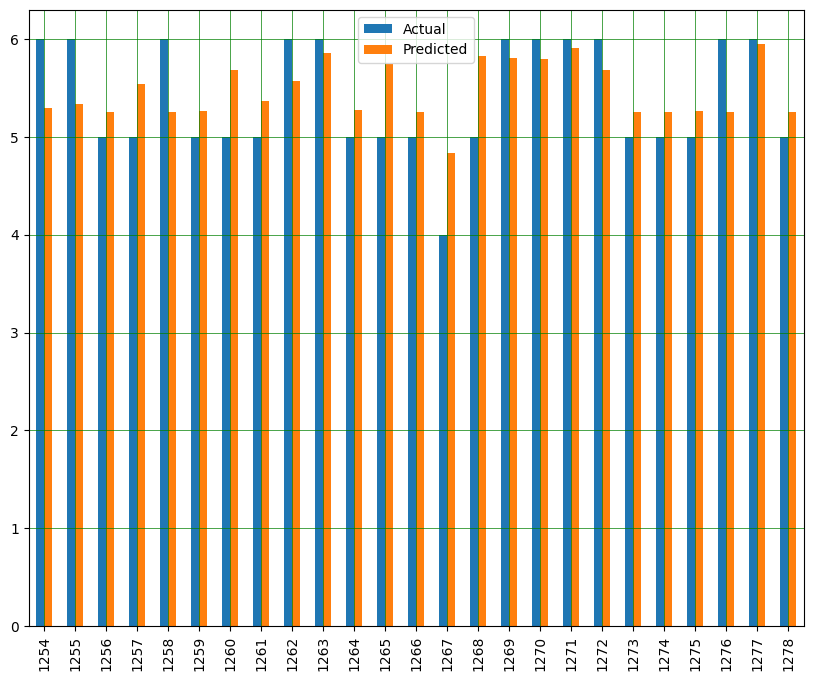

In [10]:
df1.plot(kind='bar',figsize=(10,8))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

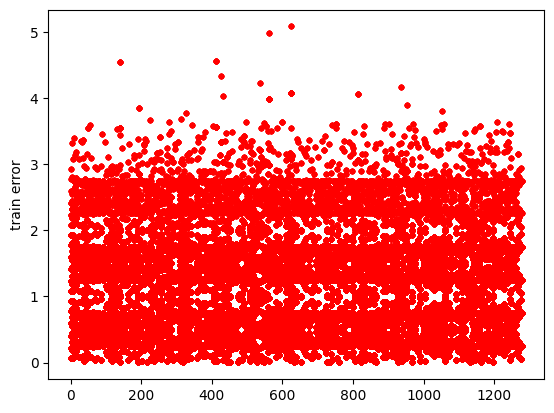

In [11]:
plt.plot(train_error,'r.')
plt.ylabel('train error')
plt.show()

In [12]:
# testing the model with the test data
prediction = estimator.predict(X_test)

test_error =  np.abs(Y_test - prediction)
mean_error = np.mean(test_error)
min_error = np.min(test_error)
max_error = np.max(test_error)
std_error = np.std(test_error)
print('\nTesting results:\nmean=',mean_error,'\nmin=',min_error,'\nmax=',max_error,'\nstd=',std_error)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 773us/step

Testing results:
mean= 0.6996092533506453 
min= 0.001628875732421875 
max= 7.053915977478027 
std= 0.5478885725467689


In [13]:
# and showing the results
df = pd.DataFrame({'Actual': Y_test, 'Predicted': prediction.ravel() })
df1 = df.tail(25)
print(df1)

     Actual  Predicted
295     6.0   5.710537
296     6.0   5.981807
297     5.0   5.764098
298     6.0   5.254329
299     5.0   5.254329
300     6.0   5.590255
301     5.0   4.360251
302     6.0   5.563814
303     6.0   5.862107
304     6.0   5.983737
305     6.0   5.962470
306     5.0   5.201662
307     5.0   5.254329
308     6.0   5.293067
309     5.0   5.592734
310     5.0   5.496089
311     6.0   6.026020
312     5.0   5.560232
313     5.0   5.648232
314     5.0   5.303916
315     6.0   6.325044
316     4.0   5.916727
317     5.0   6.082147
318     4.0   5.629954
319     6.0   6.084391


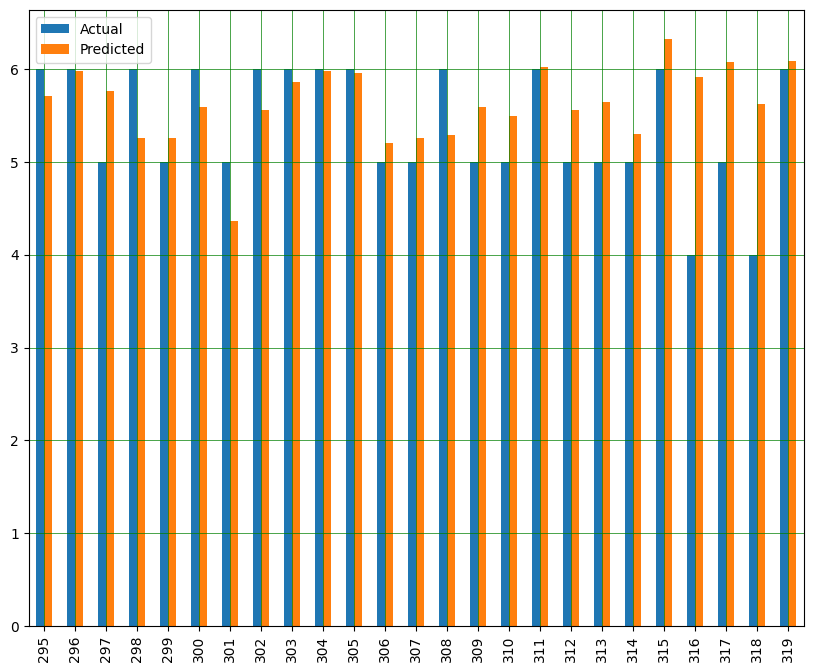

In [14]:
df1.plot(kind='bar',figsize=(10,8))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

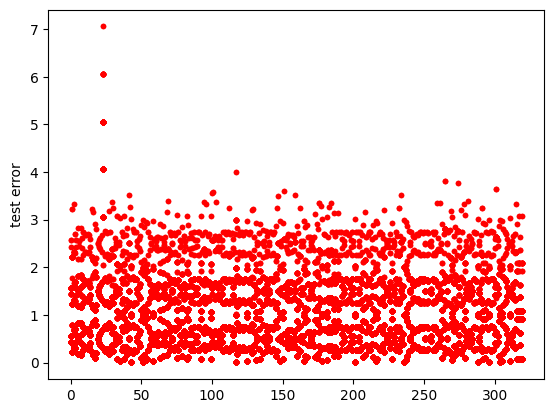

In [15]:
plt.plot(test_error,'r.')
plt.ylabel('test error')
plt.show()

##  Practices
1. train the model for 1400 epochs. what are the training and testing MAE?
2. repeat that with 6000 training epochs. what are the training and testing MAE?
3. move back to 900 training epochs. add two convolutional and one dense layer with the same features of the layers used. what are the training and testing MAE?
4. go for 6000 training epochs. Do you feel any overfitting?
5. set back everything to the original setting, then try to normalize the training and testing features and outputs using standard_scaler. Then see if anything gets better or not. You may use insttructions like what you can see in the next cell.  

#### points:
- use GPU as your runtime type
- if the notebook overflows, change the verbose to 0, e.g. verbose=0 in the training cell.

In [16]:
'''
# normalization
from sklearn.preprocessing import StandardScaler

# Create scalers
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Standardize X_train and X_test
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Standardize Y_train and Y_test (only if y is continuous, e.g., in regression)
y_train_scaled = scaler_y.fit_transform(Y_train.reshape(-1, 1))  # Reshape if needed
y_test_scaled = scaler_y.transform(Y_test.reshape(-1, 1))
'''

'\n# normalization\nfrom sklearn.preprocessing import StandardScaler\n\n# Create scalers\nscaler_X = StandardScaler()\nscaler_y = StandardScaler()\n\n# Standardize X_train and X_test\nX_train_scaled = scaler_X.fit_transform(X_train)\nX_test_scaled = scaler_X.transform(X_test)\n\n# Standardize Y_train and Y_test (only if y is continuous, e.g., in regression)\ny_train_scaled = scaler_y.fit_transform(Y_train.reshape(-1, 1))  # Reshape if needed\ny_test_scaled = scaler_y.transform(Y_test.reshape(-1, 1))\n'